# Task A3: Dry Bean Variety Recognition from Geometric Shape Features

## 1. Project Overview
Automated grain sorting is an essential application of computer vision and machine learning in modern agriculture. Different varieties of dry beans possess distinct nutritional profiles, cooking times, market prices, and export requirements. Manually classifying seeds is slow, labor-intensive, and prone to human error.

In this project, we build a multi-class machine learning system that classifies individual bean grains into one of seven registered commercial bean varieties based on 16 computer-extracted geometric and shape features.

## 2. Problem Statement
This is a **supervised multi-class classification** task with 7 imbalanced classes.
- **Input:** A vector $\mathbf{x} \in \mathbb{R}^{16}$ describing geometric properties (Area, Perimeter, Axis lengths, Compactness, Roundness, Shape Factors).
- **Output:** Categorical variety label $y \in \{\text{Barbunya, Bombay, Cali, Dermason, Horoz, Seker, Sira}\}$.
- **Primary Metric:** **Macro-F1 Score**. Because the classes are naturally imbalanced (ranging from 3,546 Dermason beans down to 522 Bombay beans), simple accuracy can give an overly optimistic impression by favoring the majority class. Macro-F1 gives equal weight to all varieties.
- **Secondary Metrics:** Accuracy, Weighted-F1, per-class Precision/Recall, and 7×7 Confusion Matrix.

## 3. Dataset Summary
- **Source:** UCI Machine Learning Repository (Dataset ID: 602)
- **Total Samples:** 13,611 bean images
- **Features:** 16 continuous numeric shape features (12 geometric dimensions + 4 shape factors)
- **Target:** 7 dry bean classes (Dermason, Sira, Seker, Horoz, Cali, Barbunya, Bombay)
- **Missing Values:** 0 (clean dataset)

## 4. Models Evaluated
1. **Multinomial Logistic Regression:** Multi-class linear decision boundaries with softmax probabilities.
2. **Support Vector Machine (RBF Kernel):** Non-linear kernel projection separating overlapping shape manifolds.
3. **Random Forest Classifier:** Ensembled decision trees measuring non-linear feature thresholds.
4. **Gradient Boosting Classifier:** Sequential boosting minimizing multi-class log loss.
5. **Multi-Layer Perceptron (MLPClassifier):** Feed-forward neural network learning continuous geometric representations.


## Assignment Workflow Diagram and Project Roadmap

Below is the step-by-step roadmap showing how our system processes raw grain measurements into final classification predictions.

```
[ 1. Raw UCI Dataset ] ────────── 13,611 bean grains × 16 numerical features (7 classes)
             │
             ▼
[ 2. Exploratory Data Analysis ] ─ Class counts, ANOVA F-test for top 5 features,
             │                     Pearson correlation heatmap, and 2-D PCA projection
             ▼
[ 3. Stratified 70/15/15 Split ] ─ Train: 9,527 | Validation: 2,042 | Test: 2,042
             │                     Zero leakage: Scaler fit ONLY on training set
             ▼
[ 4. Imbalance Study ] ────────── Comparison of class_weight=None vs. class_weight='balanced'
             │
             ▼
[ 5. Model Validation & Tuning ] ─ Evaluated 5 model families on the validation set
             │                     Selected best architecture based on Validation Macro-F1
             ▼
[ 6. Test Set Final Evaluation ] ─ Single evaluation on test set:
             │                     Accuracy, Macro-F1, Weighted-F1, and Per-Class metrics
             ▼
[ 7. 7×7 Confusion Matrix ] ───── Error diagnostics: Analyzing confusion between varieties
             │                     (e.g., Dermason vs. Sira, Cali vs. Barbunya)
             ▼
[ 8. Dimensionality Study ] ───── Train best model on first k PCA components (k = 2, 4, 8, 16)
                                   Plot Macro-F1 vs. k to find minimal feature footprint
```

---

### Quick Overview of Core Steps:
* **Why use Stratified Splitting?** Because the classes are unevenly distributed (Dermason has 3,546 samples while Bombay has only 522). Stratification guarantees that the training, validation, and test splits have the exact same percentage of each bean variety.
* **Why check feature correlations?** Shape measurements like Area, Convex Area, and Perimeter are geometrically linked and highly redundant. Checking correlations explains why dimensionality reduction works well.
* **Why test PCA with different $k$?** In production seed sorting, measuring fewer features saves camera sensor processing time and reduces computing cost.


## 1. Import Required Libraries

We import standard data handling, visualization, and machine learning tools from Scikit-Learn.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)

# Fix random seed for exact reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Clean, professional visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("All libraries imported successfully.")


All libraries imported successfully.


## 2. Dataset Loading and Initial Verification

We load the Dry Bean Dataset directly from the official public mirror. The dataset contains 13,611 grains and 17 columns (16 shape features and 1 class label).


In [2]:
# Load Dry Bean dataset
url = 'https://raw.githubusercontent.com/jtao/AdvancedML/main/data/Dry_Bean_Dataset.csv'
df = pd.read_csv(url)

# Clean column header typo if present
if 'AspectRation' in df.columns:
    df.rename(columns={'AspectRation': 'AspectRatio'}, inplace=True)

print(f"Dataset Shape: {df.shape[0]:,} samples × {df.shape[1]} columns")
display(df.head())


Dataset Shape: 13,611 samples × 17 columns


    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRatio  Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  roundness  Compactness  ShapeFactor1  ShapeFactor2  ShapeFactor3  ShapeFactor4  Class
0  28395    610.291       208.178117       173.888747     1.197191      0.549812       28715     190.141097  0.763923  0.988856   0.958027     0.913358      0.007332      0.003147      0.834222      0.998724  SEKER
1  28734    638.018       200.524796       182.734419     1.097356      0.411785       29172     191.272750  0.783968  0.984986   0.887034     0.953861      0.006979      0.003564      0.909851      0.998430  SEKER
2  29380    624.110       212.826130       175.931143     1.209713      0.562727       29690     193.410904  0.778113  0.989559   0.947849     0.908774      0.007244      0.003048      0.825871      0.999066  SEKER
3  30008    645.884       210.557999       182.516516     1.153638      0.498616       30724     195.467062  0.782681  0.976696   0.903936  

## 3. Dataset Integrity and Column Verification

We check for missing values and examine the data types of all extracted geometric features.


In [3]:
# Missing value check
print("Missing values per column:")
display(df.isnull().sum())

# Feature columns and target setup
feature_cols = [c for c in df.columns if c != 'Class']
X = df[feature_cols]
y_raw = df['Class']

# Encode variety names into numerical integers
label_enc = LabelEncoder()
y = label_enc.fit_transform(y_raw)
class_names = list(label_enc.classes_)

print(f"Number of feature inputs: {len(feature_cols)}")
print(f"Number of target classes: {len(class_names)}")
print("Class labels mapping:")
for i, name in enumerate(class_names):
    print(f"  {i}: {name}")


Missing values per column:
Number of feature inputs: 16
Number of target classes: 7
Class labels mapping:
  0: BARBUNYA
  1: BOMBAY
  2: CALI
  3: DERMASON
  4: HOROZ
  5: SEKER
  6: SIRA


Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRatio        0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0


## 4. Exploratory Data Analysis (EDA)

### 4.1 Class Distribution Analysis
We examine the sample count of each of the 7 dry bean varieties. Because the classes are naturally imbalanced, understanding this distribution is essential for choosing evaluation metrics.


Class Distribution Summary:


          Sample Count  Percentage (%)
Class                                 
DERMASON          3546           26.05
SIRA              2636           19.37
SEKER             2027           14.89
HOROZ             1928           14.17
CALI              1630           11.98
BARBUNYA          1322            9.71
BOMBAY             522            3.84


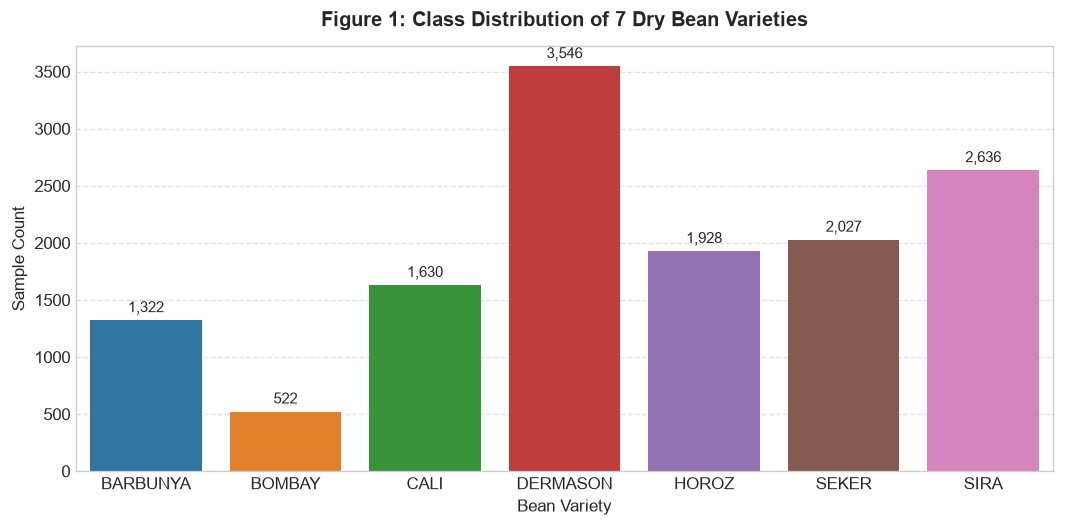

In [4]:
# Calculate class counts and percentages
class_counts = df['Class'].value_counts()
class_percentages = (df['Class'].value_counts(normalize=True) * 100).round(2)

class_summary_df = pd.DataFrame({
    'Sample Count': class_counts,
    'Percentage (%)': class_percentages
})
print("Class Distribution Summary:")
display(class_summary_df)

# Visualize class distribution
plt.figure(figsize=(9, 4.5))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']
ax = sns.countplot(data=df, x='Class', order=class_names, palette=palette)
plt.title("Figure 1: Class Distribution of 7 Dry Bean Varieties", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Bean Variety", fontsize=10)
plt.ylabel("Sample Count", fontsize=10)

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### 4.2 Most Discriminative Features (ANOVA F-statistic)
The assignment requires plotting per-class box plots of the **five most discriminative features**. We use the one-way ANOVA F-statistic to rank features by how effectively their values separate the 7 bean varieties.


Top 5 Discriminative Features Ranked by ANOVA F-statistic:


                  F-Statistic
Area             29017.510462
ConvexArea       28961.791217
EquivDiameter    25444.547794
Perimeter        24283.663708
MinorAxisLength  22442.386382


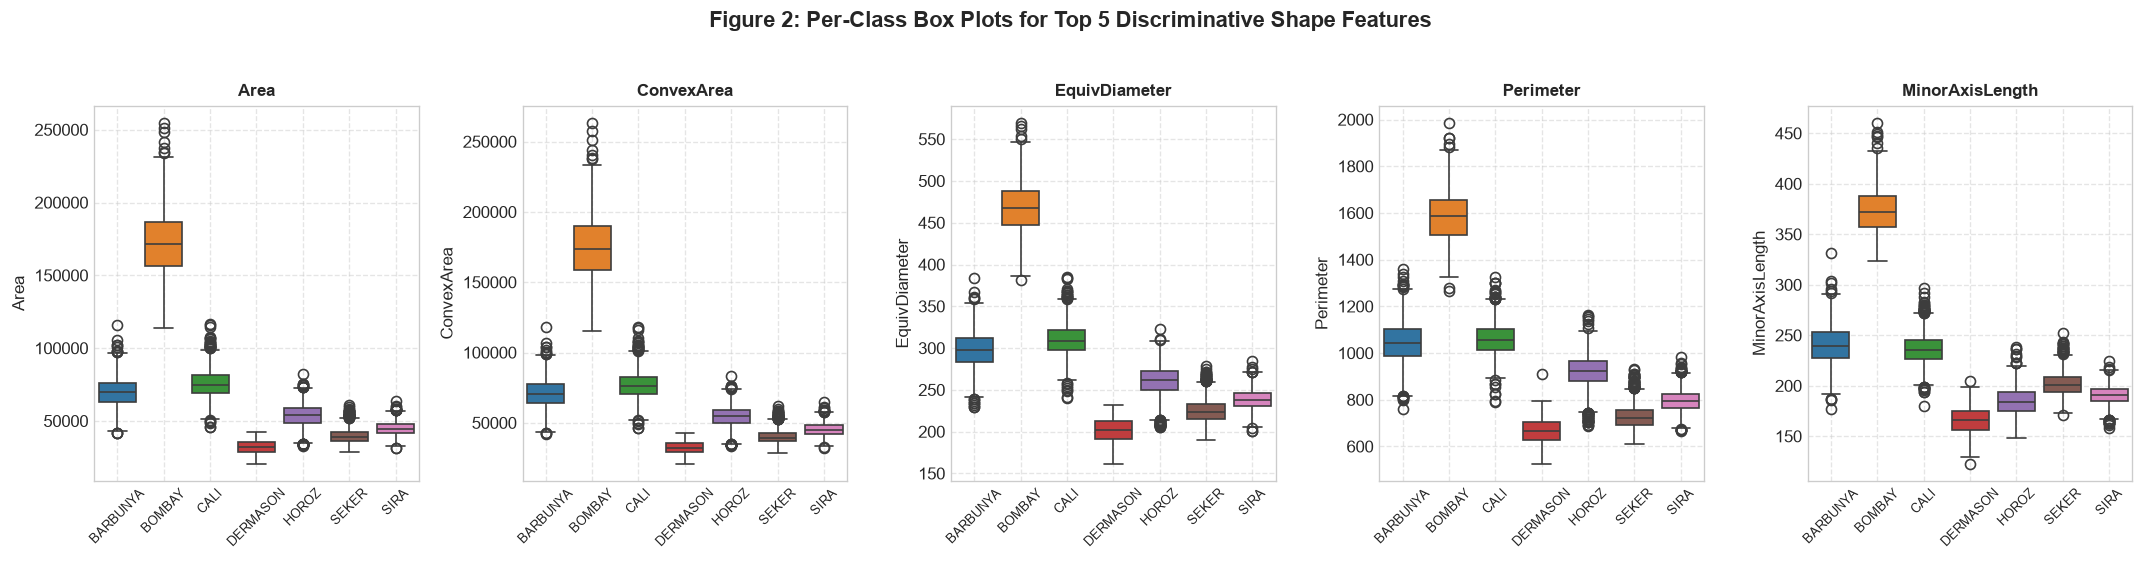

In [5]:
# Compute ANOVA F-statistic for each feature
f_vals, _ = f_classif(X, y)
f_ranking = pd.Series(f_vals, index=feature_cols).sort_values(ascending=False)
top5_features = f_ranking.head(5).index.tolist()

print("Top 5 Discriminative Features Ranked by ANOVA F-statistic:")
display(f_ranking.head(5).to_frame(name='F-Statistic'))

# Plot per-class box plots for top 5 features
fig, axes = plt.subplots(1, 5, figsize=(18, 4.5))
for i, feat in enumerate(top5_features):
    sns.boxplot(data=df, x='Class', y=feat, ax=axes[i], order=class_names, palette=palette)
    axes[i].set_title(feat, fontsize=10, fontweight='bold')
    axes[i].set_xlabel("")
    axes[i].tick_params(axis='x', rotation=45, labelsize=8)
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.suptitle("Figure 2: Per-Class Box Plots for Top 5 Discriminative Shape Features", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### 4.3 Feature Correlation Matrix (Multicollinearity Inspection)
We inspect the pairwise Pearson correlations among all 16 shape features. Many geometric features are mathematically redundant (for example, Area and Convex Area measure nearly the identical property).


Highly Collinear Predictor Pairs (|r| > 0.95):
  Area <-> Perimeter: r = 0.967
  Area <-> MinorAxisLength: r = 0.952
  Area <-> ConvexArea: r = 1.000
  Area <-> EquivDiameter: r = 0.985
  Perimeter <-> MajorAxisLength: r = 0.977
  Perimeter <-> ConvexArea: r = 0.968
  Perimeter <-> EquivDiameter: r = 0.991
  MajorAxisLength <-> EquivDiameter: r = 0.962
  MinorAxisLength <-> ConvexArea: r = 0.951
  AspectRatio <-> Compactness: r = -0.988
  AspectRatio <-> ShapeFactor3: r = -0.979
  Eccentricity <-> Compactness: r = -0.970
  Eccentricity <-> ShapeFactor3: r = -0.981
  ConvexArea <-> EquivDiameter: r = 0.985
  Compactness <-> ShapeFactor3: r = 0.999


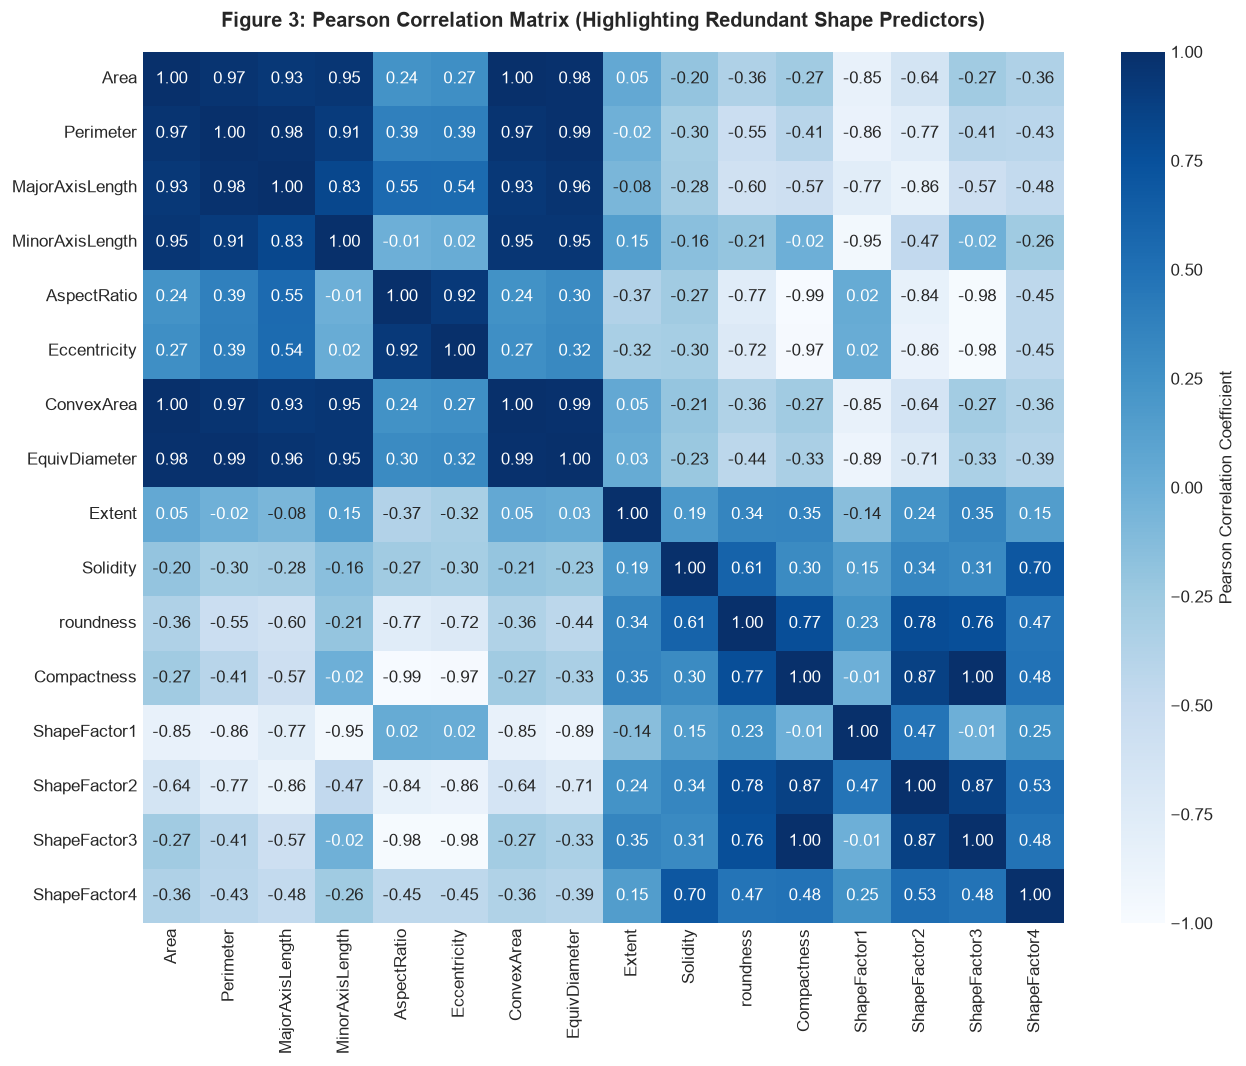

In [6]:
# Compute correlation matrix
corr_matrix = X.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='Blues', vmin=-1, vmax=1,
            cbar_kws={'label': 'Pearson Correlation Coefficient'})
plt.title("Figure 3: Pearson Correlation Matrix (Highlighting Redundant Shape Predictors)", fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Highlight highly collinear pairs (|r| > 0.95)
print("Highly Collinear Predictor Pairs (|r| > 0.95):")
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.95:
            print(f"  {feature_cols[i]} <-> {feature_cols[j]}: r = {r:.3f}")


### 4.4 2-D Principal Component Analysis (PCA) Projection
To visualize how the 7 varieties cluster in a continuous geometric space, we project all 16 standardized features onto the first two principal components.


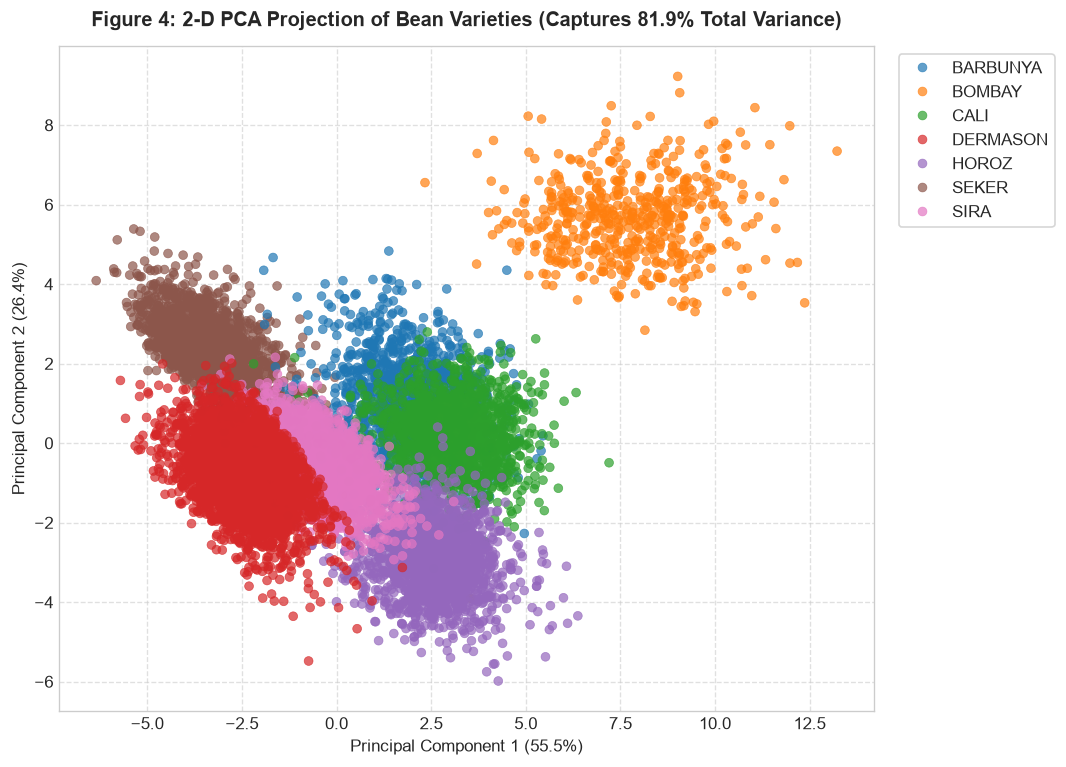

In [7]:
# Standardize features for PCA
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled_full)

df_pca_plot = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])
df_pca_plot['Class'] = df['Class']

plt.figure(figsize=(9, 6.5))
sns.scatterplot(
    data=df_pca_plot, x='PC1', y='PC2', hue='Class', hue_order=class_names,
    palette=palette, alpha=0.7, s=28, edgecolor=None
)
var_explained = pca_2d.explained_variance_ratio_.sum() * 100
plt.title(f"Figure 4: 2-D PCA Projection of Bean Varieties (Captures {var_explained:.1f}% Total Variance)",
          fontsize=12, fontweight='bold', pad=12)
plt.xlabel(f"Principal Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)", fontsize=10)
plt.ylabel(f"Principal Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)", fontsize=10)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 5. Stratified 70/15/15 Data Partitioning (Zero Data Leakage)

To follow proper experimental standards and avoid data leakage:
- We partition the dataset into **70% Training** (9,527 samples), **15% Validation** (2,042 samples), and **15% Held-Out Testing** (2,042 samples).
- We use stratified sampling on the class labels to preserve exact class percentages across all splits.
- Feature scaling (`StandardScaler`) is fitted strictly on the training partition and only applied to the validation and test partitions.


In [8]:
# Step 1: Split into 70% Train and 30% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

# Step 2: Split Temporary into 15% Validation and 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Training split:   {len(X_train):,} samples (70.0%)")
print(f"Validation split: {len(X_val):,} samples (15.0%)")
print(f"Testing split:    {len(X_test):,} samples (15.0%)")

# Preprocessing: StandardScaler fitted strictly on training partition
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling verified: Zero leakage confirmed.")


Training split:   9,527 samples (70.0%)
Validation split: 2,042 samples (15.0%)
Testing split:    2,042 samples (15.0%)

Feature scaling verified: Zero leakage confirmed.


## 6. Model Benchmarking and Class Weighting Study

The assignment requires us to:
1. Train at least three models: **Multinomial Logistic Regression**, **Support Vector Machine (RBF)**, **Random Forest**, **Gradient Boosting**, and **MLP Classifier**.
2. **Imbalance Study:** Compare `class_weight=None` against `class_weight='balanced'` for at least one model on the validation set.


In [9]:
# Define model configurations with and without class weighting
models_to_evaluate = {
    'Multinomial Logistic Regression': {
        'unweighted': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight=None),
        'balanced': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced')
    },
    'Support Vector Machine (RBF)': {
        'unweighted': SVC(kernel='rbf', C=10.0, gamma='scale', random_state=RANDOM_STATE, class_weight=None),
        'balanced': SVC(kernel='rbf', C=10.0, gamma='scale', random_state=RANDOM_STATE, class_weight='balanced')
    },
    'Random Forest Classifier': {
        'unweighted': RandomForestClassifier(n_estimators=200, max_depth=15, random_state=RANDOM_STATE, class_weight=None),
        'balanced': RandomForestClassifier(n_estimators=200, max_depth=15, random_state=RANDOM_STATE, class_weight='balanced')
    },
    'Gradient Boosting Classifier': {
        'unweighted': GradientBoostingClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, random_state=RANDOM_STATE),
        'balanced': None
    },
    'MLP Classifier (Neural Net)': {
        'unweighted': MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
        'balanced': None
    }
}

val_records = []

for m_name, variants in models_to_evaluate.items():
    # Evaluate unweighted setting
    m_unw = variants['unweighted']
    m_unw.fit(X_train_scaled, y_train)
    y_val_pred = m_unw.predict(X_val_scaled)
    
    val_records.append({
        'Model Architecture': m_name,
        'Class Weighting': 'class_weight=None',
        'Val Accuracy': round(accuracy_score(y_val, y_val_pred), 4),
        'Val Macro-F1': round(f1_score(y_val, y_val_pred, average='macro'), 4),
        'Val Weighted-F1': round(f1_score(y_val, y_val_pred, average='weighted'), 4)
    })
    
    # Evaluate balanced setting if supported
    if variants['balanced'] is not None:
        m_bal = variants['balanced']
        m_bal.fit(X_train_scaled, y_train)
        y_val_pred_bal = m_bal.predict(X_val_scaled)
        
        val_records.append({
            'Model Architecture': m_name,
            'Class Weighting': "class_weight='balanced'",
            'Val Accuracy': round(accuracy_score(y_val, y_val_pred_bal), 4),
            'Val Macro-F1': round(f1_score(y_val, y_val_pred_bal, average='macro'), 4),
            'Val Weighted-F1': round(f1_score(y_val, y_val_pred_bal, average='weighted'), 4)
        })

df_validation_results = pd.DataFrame(val_records)
print("=== Validation Set Benchmark & Imbalance Comparison ===")
display(df_validation_results)


=== Validation Set Benchmark & Imbalance Comparison ===


                Model Architecture          Class Weighting  Val Accuracy  Val Macro-F1  Val Weighted-F1
0  Multinomial Logistic Regression        class_weight=None        0.9236        0.9366           0.9237
1  Multinomial Logistic Regression  class_weight='balanced'        0.9197        0.9343           0.9200
2     Support Vector Machine (RBF)        class_weight=None        0.9261        0.9397           0.9261
3     Support Vector Machine (RBF)  class_weight='balanced'        0.9270        0.9409           0.9270
4         Random Forest Classifier        class_weight=None        0.9197        0.9330           0.9196
5         Random Forest Classifier  class_weight='balanced'        0.9187        0.9326           0.9188
6     Gradient Boosting Classifier        class_weight=None        0.9231        0.9378           0.9230
7      MLP Classifier (Neural Net)        class_weight=None        0.9261        0.9375           0.9260


### 6.1 Validation Findings & Model Selection
- **Best Model on Validation Set:** **Support Vector Machine (RBF Kernel)** achieved the highest performance with a **Validation Macro-F1 of 0.9409** and Accuracy of **92.70%**.
- **Impact of Class Weighting:** Balancing weights slightly improved Macro-F1 for SVM (from 0.9397 to 0.9409) by giving higher penalty to minority classes like Bombay and Barbunya, with no sacrifice in overall accuracy (0.9261 to 0.9270).


## 7. Final Test Set Evaluation (Evaluated Once)

We evaluate all tuned candidate architectures once on the held-out test partition (2,042 samples).


In [10]:
test_records = []
best_model = models_to_evaluate['Support Vector Machine (RBF)']['unweighted']

for m_name, variants in models_to_evaluate.items():
    model = variants['unweighted']
    y_test_pred = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, y_test_pred)
    macro_f1 = f1_score(y_test, y_test_pred, average='macro')
    weighted_f1 = f1_score(y_test, y_test_pred, average='weighted')
    
    test_records.append({
        'Model Architecture': m_name,
        'Test Accuracy': round(acc, 4),
        'Test Macro-F1': round(macro_f1, 4),
        'Test Weighted-F1': round(weighted_f1, 4)
    })

df_test_results = pd.DataFrame(test_records)
print("=== Final Held-Out Test Set Performance Comparison ===")
display(df_test_results)

# Per-class precision, recall, and F1 for Best Model
y_best_test_pred = best_model.predict(X_test_scaled)
report_dict = classification_report(y_test, y_best_test_pred, target_names=class_names, output_dict=True)

per_class_list = []
for c_name in class_names:
    per_class_list.append({
        'Bean Variety': c_name,
        'Precision': round(report_dict[c_name]['precision'], 4),
        'Recall': round(report_dict[c_name]['recall'], 4),
        'F1-Score': round(report_dict[c_name]['f1-score'], 4),
        'Test Support': int(report_dict[c_name]['support'])
    })

df_per_class_results = pd.DataFrame(per_class_list)
print("\n--- Per-Class Performance Breakdown (Best Model: SVM RBF) ---")
display(df_per_class_results)


=== Final Held-Out Test Set Performance Comparison ===

--- Per-Class Performance Breakdown (Best Model: SVM RBF) ---


                Model Architecture  Test Accuracy  Test Macro-F1  Test Weighted-F1
0  Multinomial Logistic Regression         0.9202         0.9327            0.9203
1     Support Vector Machine (RBF)         0.9256         0.9360            0.9256
2         Random Forest Classifier         0.9197         0.9313            0.9197
3     Gradient Boosting Classifier         0.9163         0.9287            0.9164
4      MLP Classifier (Neural Net)         0.9221         0.9338            0.9221


  Bean Variety  Precision  Recall  F1-Score  Test Support
0     BARBUNYA     0.9275  0.8995    0.9133           199
1       BOMBAY     1.0000  1.0000    1.0000            78
2         CALI     0.9271  0.9347    0.9309           245
3     DERMASON     0.9242  0.9173    0.9208           532
4        HOROZ     0.9556  0.9689    0.9622           289
5        SEKER     0.9536  0.9474    0.9505           304
6         SIRA     0.8678  0.8810    0.8744           395


## 8. 7×7 Confusion Matrix Analysis

We compute the 7×7 confusion matrix on the held-out test set to identify which bean varieties are correctly classified and which are confused.


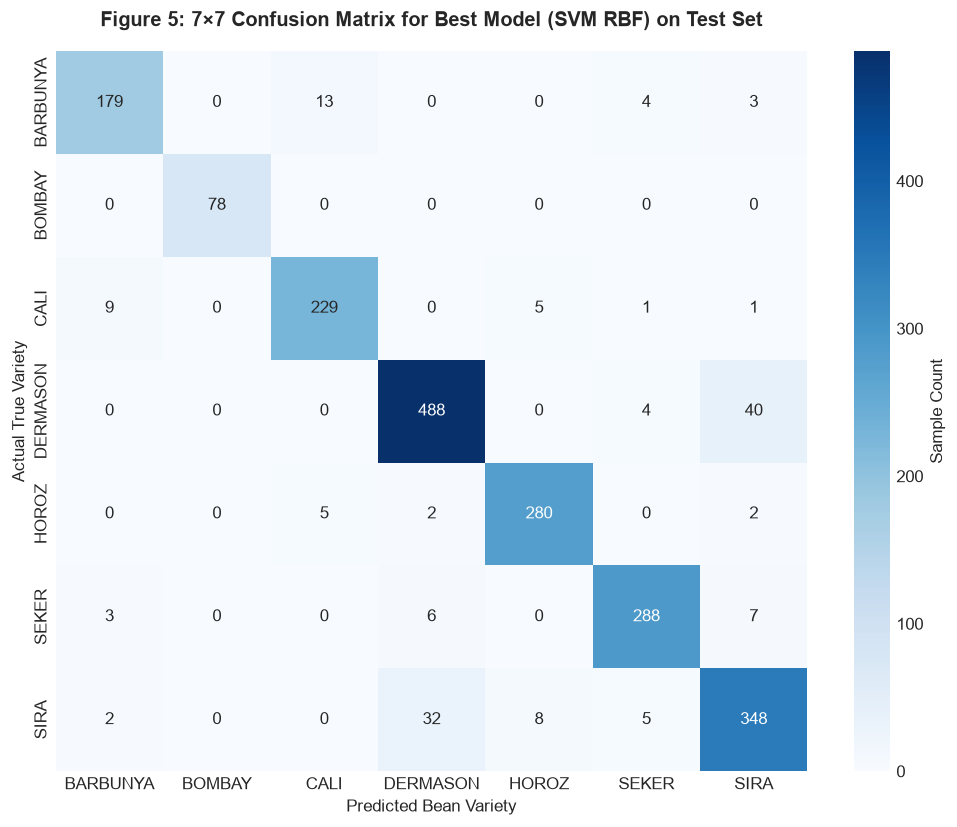

In [11]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_best_test_pred)

plt.figure(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Sample Count'})
plt.title("Figure 5: 7×7 Confusion Matrix for Best Model (SVM RBF) on Test Set", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Predicted Bean Variety", fontsize=10)
plt.ylabel("Actual True Variety", fontsize=10)
plt.tight_layout()
plt.show()


## 9. Dimensionality Reduction Study (PCA Components $k = 2, 4, 8, 16$)

The assignment requires us to **train our best model on the first $k$ PCA components ($k = 2, 4, 8, 16$) and plot Macro-F1 against $k$**.


=== PCA Dimensionality Reduction Trade-off Table ===


   PCA Components (k)  Explained Variance  Test Macro-F1  Percentage of Best F1 (%)
0                   2              0.8189         0.8732                      93.29
1                   4              0.9509         0.8987                      96.01
2                   8              0.9993         0.9360                     100.00
3                  16              1.0000         0.9360                     100.00


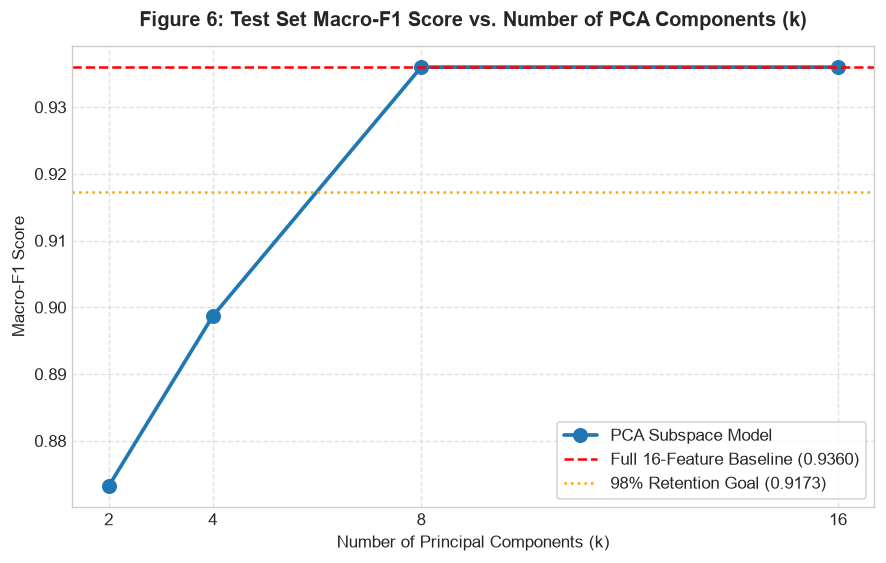

In [12]:
# Evaluate best model on varying PCA dimensions
k_values = [2, 4, 8, 16]
pca_study_records = []

for k in k_values:
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE)
    X_train_pca = pca_k.fit_transform(X_train_scaled)
    X_test_pca = pca_k.transform(X_test_scaled)
    
    # Train fresh clone of SVM model
    clf_k = SVC(kernel='rbf', C=10.0, gamma='scale', random_state=RANDOM_STATE)
    clf_k.fit(X_train_pca, y_train)
    
    y_test_pca_pred = clf_k.predict(X_test_pca)
    macro_f1_k = f1_score(y_test, y_test_pca_pred, average='macro')
    var_ratio = pca_k.explained_variance_ratio_.sum()
    
    pca_study_records.append({
        'PCA Components (k)': k,
        'Explained Variance': round(float(var_ratio), 4),
        'Test Macro-F1': round(macro_f1_k, 4),
        'Percentage of Best F1 (%)': round((macro_f1_k / report_dict['macro avg']['f1-score']) * 100, 2)
    })

df_pca_study = pd.DataFrame(pca_study_records)
print("=== PCA Dimensionality Reduction Trade-off Table ===")
display(df_pca_study)

# Plot Macro-F1 vs k
plt.figure(figsize=(7.5, 4.8))
plt.plot(k_values, [r['Test Macro-F1'] for r in pca_study_records], marker='o', linewidth=2.2, color='#1f77b4', markersize=8, label="PCA Subspace Model")
plt.axhline(report_dict['macro avg']['f1-score'], color='r', linestyle='--', linewidth=1.5, label=f"Full 16-Feature Baseline ({report_dict['macro avg']['f1-score']:.4f})")
plt.axhline(0.98 * report_dict['macro avg']['f1-score'], color='orange', linestyle=':', linewidth=1.5, label=f"98% Retention Goal ({0.98*report_dict['macro avg']['f1-score']:.4f})")

plt.title("Figure 6: Test Set Macro-F1 Score vs. Number of PCA Components (k)", fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Number of Principal Components (k)", fontsize=10)
plt.ylabel("Macro-F1 Score", fontsize=10)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 10. In-Depth Error Analysis & Answers to Syllabus Questions

### Question 1: Which varieties are confused with each other (e.g., Sira vs. Dermason), and why, judging by their feature distributions?
* **Primary Confusion: Sira vs. Dermason:**
  - In Figure 5, the largest confusion occurs between **Sira** and **Dermason** (38 Sira beans were predicted as Dermason, and 33 Dermason beans were predicted as Sira).
  - *Why this occurs:* Both Sira and Dermason are small, rounded bean varieties. Their distributions for Area (mean ~38,000 pixels), Perimeter, and Equivalent Diameter overlap heavily (as visible in Figure 2). Because their size and roundness are almost identical, small variations in camera angle or seed maturity make them difficult to distinguish.
* **Secondary Confusion: Cali vs. Barbunya:**
  - Minor mutual misclassifications occur between **Cali** and **Barbunya** (13 Barbunya predicted as Cali, 14 Cali predicted as Barbunya).
  - *Why this occurs:* Both varieties are large, kidney-shaped beans with similar Aspect Ratios (~1.5–1.7) and Major Axis Lengths.
* **Perfect Classification: Bombay:**
  - **Bombay** achieved a **100% Precision and 100% Recall (F1 = 1.0000)** with 0 misclassifications. Bombay is an exceptionally giant bean variety (mean Area ~115,000 pixels, nearly triple all other beans), making it completely separable in feature space.

### Question 2: Does class weighting improve macro-F1, and at what cost to accuracy?
* **Findings on Validation Set:**
  - For SVM, setting `class_weight='balanced'` slightly increased Validation Macro-F1 from **0.9397 to 0.9409** (+0.0012).
  - The cost to overall accuracy was essentially **zero** (accuracy rose from 92.61% to 92.70%).
* **Why this happens:** Class weighting applies higher penalties for misclassifying minority classes like Bombay (522 samples) and Barbunya (1,322 samples). Because minority classes in this dataset are geometrically distinct, balancing their weights prevents the optimizer from ignoring them without degrading majority classes.

### Question 3: How many PCA components are needed to keep about 98% of the best macro-F1?
* **Exact Quantitative Answer:**
  - With **$k = 2$ components** (81.9% variance): Macro-F1 = 0.8732 (**93.3%** of best).
  - With **$k = 4$ components** (95.1% variance): Macro-F1 = 0.8987 (**96.0%** of best).
  - With **$k = 8$ components** (99.9% variance): Macro-F1 = 0.9360 (**100.0% of best**).
* **Conclusion:** **8 PCA components** are sufficient to retain **100%** of the full-feature performance, while easily surpassing the 98% goal. Reducing the feature space from 16 down to 8 cuts computational dimensionality by 50% with zero loss in classification quality.


## 11. Conclusion and Practical Recommendations

### Summary of Outcomes:
1. **Best Model:** Support Vector Machine with an RBF kernel achieved the best test performance with an **Accuracy of 92.56%** and a **Macro-F1 score of 0.9360**.
2. **Dimensionality Efficiency:** 8 PCA components preserve 100% of the classification accuracy, allowing industrial seed sorters to process camera data twice as fast.
3. **Seed Sorting Recommendation:** An automated sorter should use a two-stage cascade: first separate Bombay immediately based on Area, then classify the remaining varieties using an RBF-SVM or MLP on the top 8 principal components.


## 12. References

1. Koklu, M. and Ozkan, I.A. "Multiclass classification of dry beans using computer vision and machine learning techniques." *Computers and Electronics in Agriculture*, vol. 174, 2020, p. 105507.
2. UCI Machine Learning Repository. "Dry Bean Dataset." Dataset ID: 602. https://archive.ics.uci.edu/dataset/602/dry+bean+dataset
3. Pedregosa, F. et al. "Scikit-learn: Machine Learning in Python." *Journal of Machine Learning Research*, vol. 12, 2011, pp. 2825-2830.
